In [11]:

import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt

from prophet import Prophet




In [12]:
df = pd.read_csv("retail_data_c.csv")
df


,InvoiceDate,CustomerID,ProductID,ProductName,Category,Quantity,UnitPrice,StockQuantity,Region,Revenue
0,2025-01-01,C1153,P010,Hair Serum,Beauty,4,586.77,95,Mumbai,2347.08
1,2025-01-01,C1150,P001,Wireless Earbuds,Electronics,3,2709.15,38,Delhi,8127.45
2,2025-01-01,C1070,P008,Backpack,Fashion,2,1510.21,50,Delhi,3020.42
3,2025-01-01,C1048,P002,Smart Watch,Electronics,2,4168.92,68,Delhi,8337.84
4,2025-01-01,C1010,P002,Smart Watch,Electronics,1,3905.15,84,Bengaluru,3905.15
...,...,...,...,...,...,...,...,...,...,...
5995,2025-12-31,C1100,P008,Backpack,Fashion,1,1576.76,69,Bengaluru,1576.76
5996,2025-12-31,C1006,P006,Green Tea,Grocery,3,323.61,15,Hyderabad,970.83
5997,2025-12-31,C1202,P006,Green Tea,Grocery,3,364.83,130,Chennai,1094.49
5998,2025-12-31,C1036,P001,Wireless Earbuds,Electronics,2,2588.30,118,Hyderabad,5176.60


In [13]:
categories = df['ProductName'].unique()
print(categories)

['Hair Serum' 'Wireless Earbuds' 'Backpack' 'Smart Watch' 'Premium Coffee'
 'Running Shoes' 'Coffee Maker' 'Face Wash' 'Air Fryer' 'Green Tea']


In [14]:
categories = ['Beauty', 'Electronics', 'Fashion', 'Grocery', 'Home']

In [15]:
for category in categories:
    print(f"--- Generating forcast {category} ---")

--- Generating forcast Beauty ---
--- Generating forcast Electronics ---
--- Generating forcast Fashion ---
--- Generating forcast Grocery ---
--- Generating forcast Home ---


In [16]:
cat_df = df[df['Category'] == category].groupby('InvoiceDate')['Revenue'].sum().reset_index()
cat_df.rename(columns={'InvoiceDate': 'ds', 'Revenue': 'y'}, inplace=True)

In [17]:
m = Prophet(daily_seasonality=True)
m.fit(cat_df)


09:48:35 - cmdstanpy - INFO - Chain [1] start processing
09:48:35 - cmdstanpy - INFO - Chain [1] done processing


In [18]:
future = m.make_future_dataframe(periods=30)
forecast = m.predict(future)

/Users/adityasharma/Library/Python/3.9/lib/python/site-packages/prophet/forecaster.py:1421: RuntimeWarning: divide by zero encountered in matmul
  comp = np.matmul(X, beta_c.transpose())
/Users/adityasharma/Library/Python/3.9/lib/python/site-packages/prophet/forecaster.py:1421: RuntimeWarning: overflow encountered in matmul
  comp = np.matmul(X, beta_c.transpose())
/Users/adityasharma/Library/Python/3.9/lib/python/site-packages/prophet/forecaster.py:1421: RuntimeWarning: invalid value encountered in matmul
  comp = np.matmul(X, beta_c.transpose())
/Users/adityasharma/Library/Python/3.9/lib/python/site-packages/prophet/forecaster.py:1565: RuntimeWarning: divide by zero encountered in matmul
  Xb_a = np.matmul(seasonal_features.values,
/Users/adityasharma/Library/Python/3.9/lib/python/site-packages/prophet/forecaster.py:1565: RuntimeWarning: overflow encountered in matmul
  Xb_a = np.matmul(seasonal_features.values,
/Users/adityasharma/Library/Python/3.9/lib/python/site-packages/prophet/

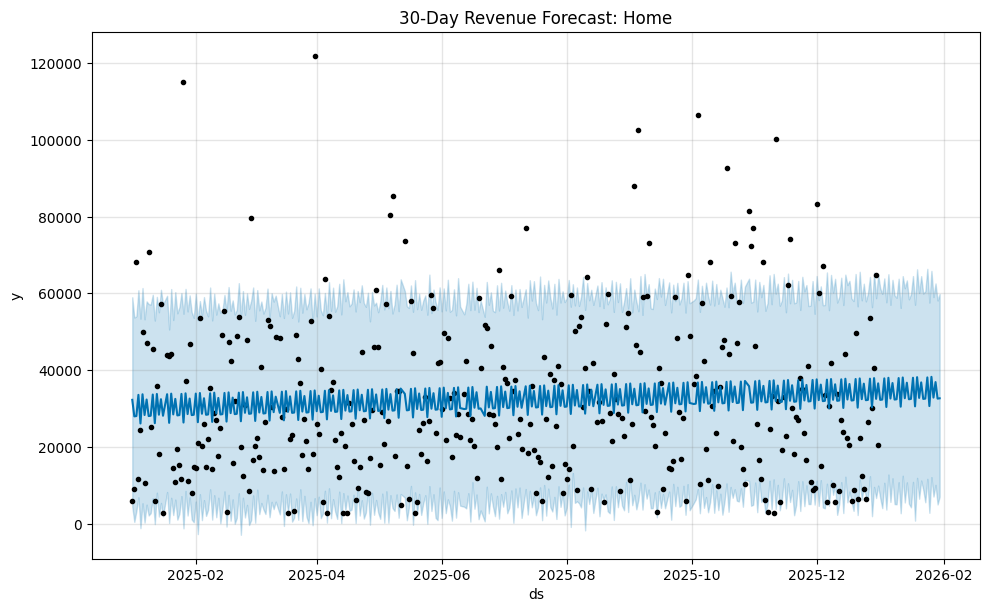

In [19]:
fig = m.plot(forecast)
plt.title(f"30-Day Revenue Forecast: {category}")
plt.show()

In [20]:
beauty_only_df = df[df['Category'] == 'Beauty'].copy()
beauty_daily = beauty_only_df.groupby('InvoiceDate')['Revenue'].sum().reset_index()
beauty_daily = beauty_daily.rename(columns={'InvoiceDate': 'ds', 'Revenue': 'y'})

In [21]:
m_beauty = Prophet(daily_seasonality=True)
m_beauty.fit(beauty_daily)

09:48:35 - cmdstanpy - INFO - Chain [1] start processing
09:48:35 - cmdstanpy - INFO - Chain [1] done processing


In [22]:
future_beauty = m_beauty.make_future_dataframe(periods=30)
forecast_beauty = m_beauty.predict(future_beauty)

/Users/adityasharma/Library/Python/3.9/lib/python/site-packages/prophet/forecaster.py:1421: RuntimeWarning: divide by zero encountered in matmul
  comp = np.matmul(X, beta_c.transpose())
/Users/adityasharma/Library/Python/3.9/lib/python/site-packages/prophet/forecaster.py:1421: RuntimeWarning: overflow encountered in matmul
  comp = np.matmul(X, beta_c.transpose())
/Users/adityasharma/Library/Python/3.9/lib/python/site-packages/prophet/forecaster.py:1421: RuntimeWarning: invalid value encountered in matmul
  comp = np.matmul(X, beta_c.transpose())
/Users/adityasharma/Library/Python/3.9/lib/python/site-packages/prophet/forecaster.py:1565: RuntimeWarning: divide by zero encountered in matmul
  Xb_a = np.matmul(seasonal_features.values,
/Users/adityasharma/Library/Python/3.9/lib/python/site-packages/prophet/forecaster.py:1565: RuntimeWarning: overflow encountered in matmul
  Xb_a = np.matmul(seasonal_features.values,
/Users/adityasharma/Library/Python/3.9/lib/python/site-packages/prophet/

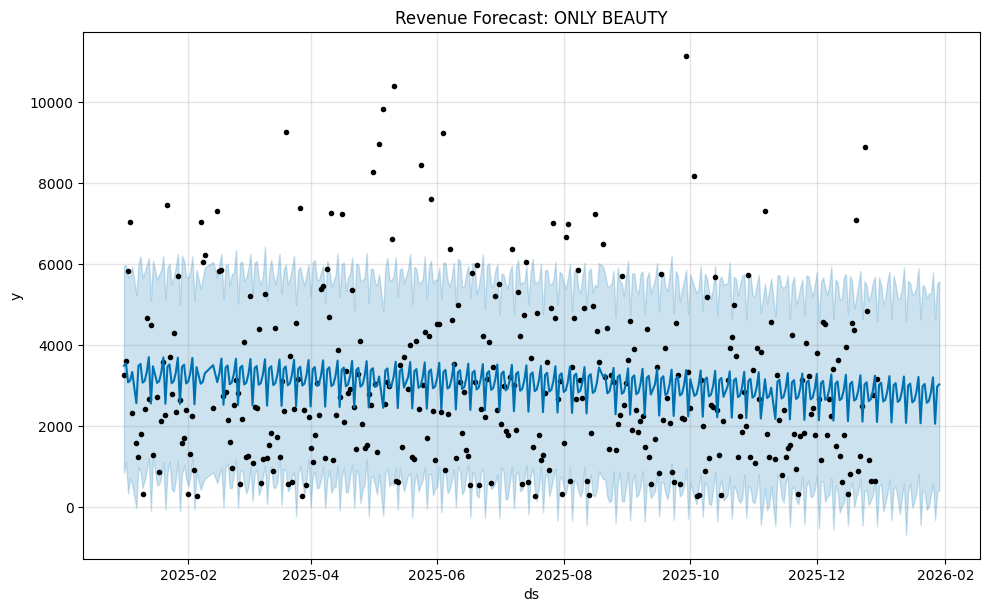

In [23]:
m_beauty.plot(forecast_beauty)
plt.title("Revenue Forecast: ONLY BEAUTY")
plt.show()

## Delhi region-wise revenue forecast

This forecast aggregates transaction revenue for Delhi by day and predicts the next 30 days. Dates without transactions are filled with zero revenue. The dataset covers one year, so this first baseline keeps seasonal components disabled.

## Other region-wise revenue forecasts

The next cell independently forecasts Mumbai, Bengaluru, Chennai, and Hyderabad using the same 30-day daily-revenue baseline as Delhi.

09:48:36 - cmdstanpy - INFO - Chain [1] start processing
09:48:36 - cmdstanpy - INFO - Chain [1] done processing


Delhi: 1,178 transactions, 365 daily observations; forecasting the next 30 days.


,ds,yhat,yhat_lower,yhat_upper
365,2026-01-01,14492.87,0.0,30950.54
366,2026-01-02,14487.03,0.0,31318.88
367,2026-01-03,14481.18,0.0,31619.09
368,2026-01-04,14475.34,0.0,30453.31
369,2026-01-05,14469.49,0.0,30574.49
370,2026-01-06,14463.65,0.0,30479.98
371,2026-01-07,14457.80,0.0,30591.52
372,2026-01-08,14451.96,0.0,30794.08
373,2026-01-09,14446.11,0.0,30268.03
374,2026-01-10,14440.27,0.0,31310.15


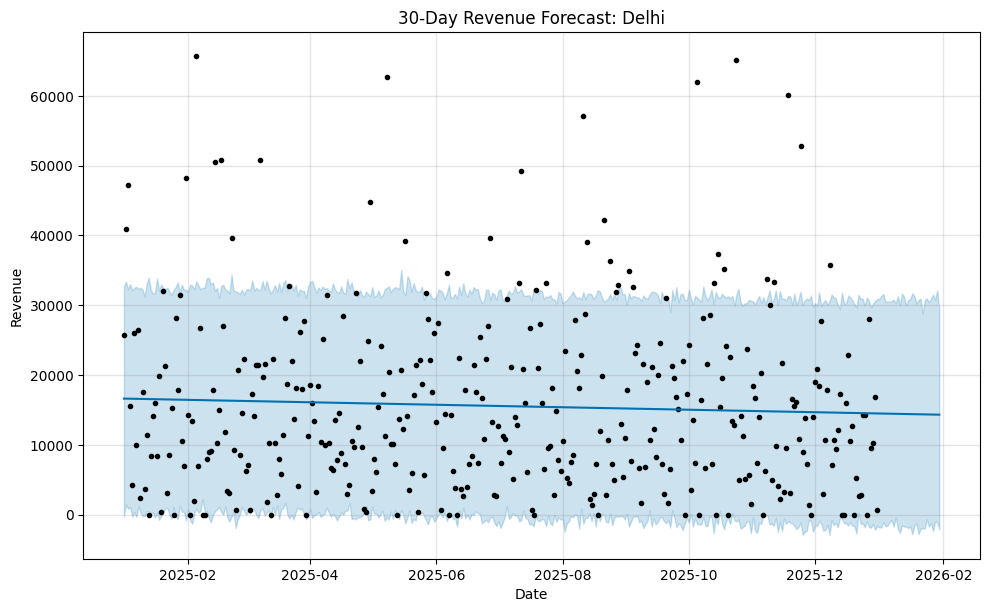

09:48:36 - cmdstanpy - INFO - Chain [1] start processing
09:48:36 - cmdstanpy - INFO - Chain [1] done processing


Mumbai: 1,232 transactions, 365 daily observations; forecasting the next 30 days.


,ds,yhat,yhat_lower,yhat_upper
365,2026-01-01,16615.63,1874.38,33197.71
366,2026-01-02,16620.62,1377.46,31107.82
367,2026-01-03,16625.61,1383.99,31863.64
368,2026-01-04,16630.60,1816.91,33144.84
369,2026-01-05,16635.59,1164.22,31858.32
370,2026-01-06,16640.58,1115.50,31053.49
371,2026-01-07,16645.57,2506.38,31700.71
372,2026-01-08,16650.56,2654.46,32393.15
373,2026-01-09,16655.55,1983.36,32954.11
374,2026-01-10,16660.54,2431.75,32663.02


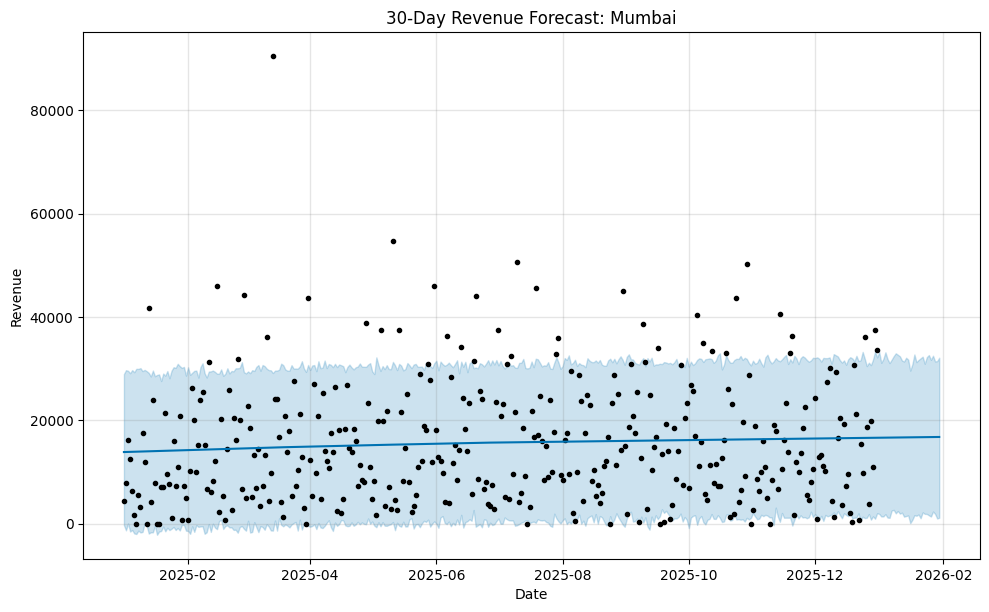

09:48:36 - cmdstanpy - INFO - Chain [1] start processing
09:48:36 - cmdstanpy - INFO - Chain [1] done processing


Bengaluru: 1,188 transactions, 365 daily observations; forecasting the next 30 days.


,ds,yhat,yhat_lower,yhat_upper
365,2026-01-01,14194.25,24.19,28364.94
366,2026-01-02,14190.78,0.00,29330.72
367,2026-01-03,14187.31,0.00,29392.79
368,2026-01-04,14183.84,0.00,29714.67
369,2026-01-05,14180.36,0.00,28406.75
370,2026-01-06,14176.89,185.94,29575.31
371,2026-01-07,14173.42,0.00,30202.69
372,2026-01-08,14169.95,0.00,30037.47
373,2026-01-09,14166.48,0.00,29954.42
374,2026-01-10,14163.01,0.00,28690.69


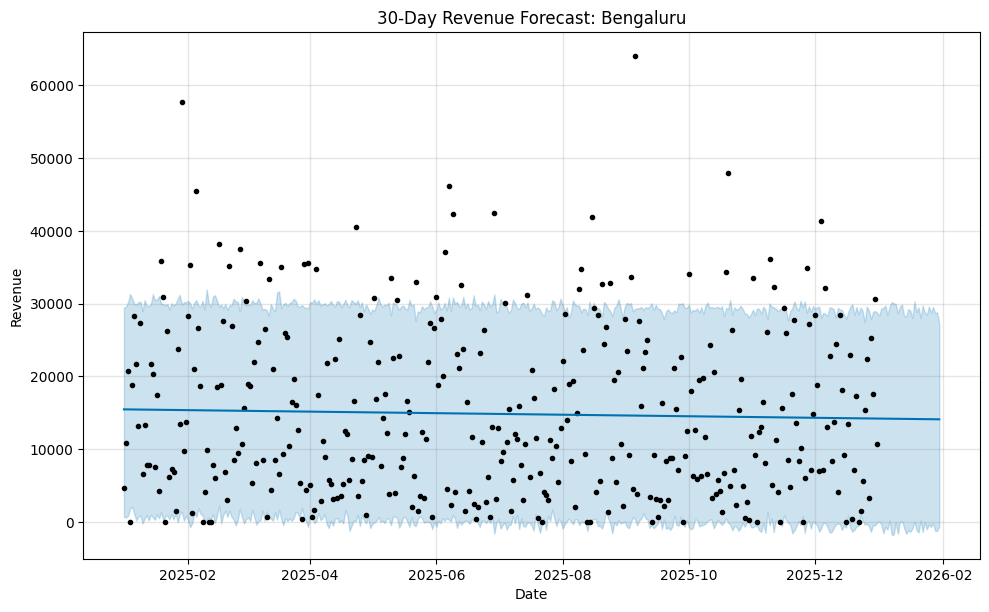

09:48:36 - cmdstanpy - INFO - Chain [1] start processing
09:48:36 - cmdstanpy - INFO - Chain [1] done processing


Chennai: 1,181 transactions, 365 daily observations; forecasting the next 30 days.


,ds,yhat,yhat_lower,yhat_upper
365,2026-01-01,18142.06,1348.31,35779.72
366,2026-01-02,18154.06,2975.48,35254.14
367,2026-01-03,18166.07,995.08,34135.30
368,2026-01-04,18178.08,2684.71,35617.64
369,2026-01-05,18190.09,2503.71,34979.45
370,2026-01-06,18202.09,1258.16,33748.10
371,2026-01-07,18214.10,1424.86,35215.74
372,2026-01-08,18226.11,3785.65,35018.64
373,2026-01-09,18238.12,2882.99,34805.99
374,2026-01-10,18250.13,2890.78,33908.83


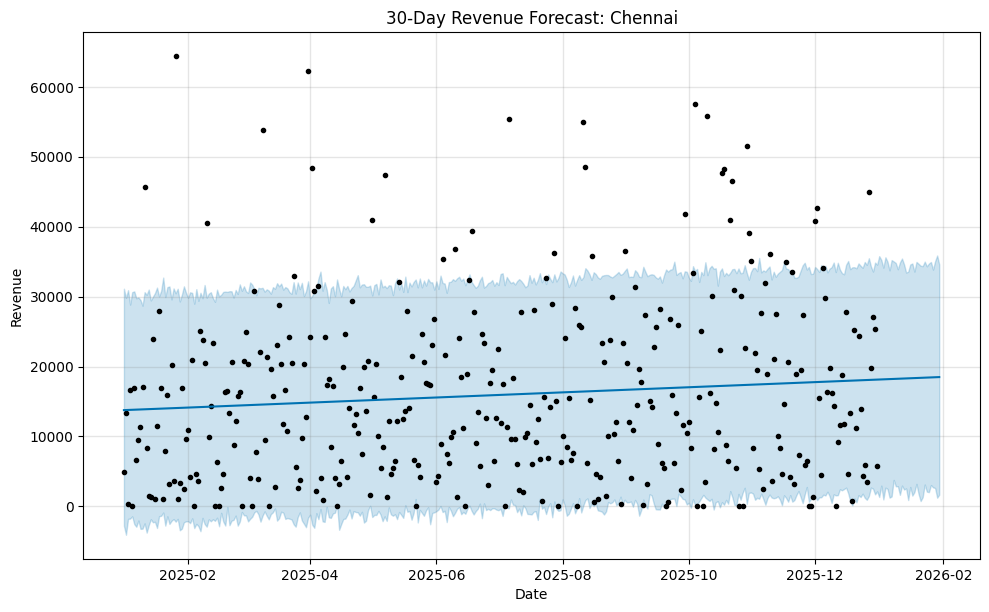

09:48:36 - cmdstanpy - INFO - Chain [1] start processing
09:48:36 - cmdstanpy - INFO - Chain [1] done processing


Hyderabad: 1,221 transactions, 364 daily observations; forecasting the next 30 days.


,ds,yhat,yhat_lower,yhat_upper
364,2026-01-01,17084.49,76.75,33884.29
365,2026-01-02,17087.49,0.00,34642.44
366,2026-01-03,17090.49,752.39,34706.06
367,2026-01-04,17093.49,0.00,34622.80
368,2026-01-05,17096.49,257.80,35334.31
369,2026-01-06,17099.48,0.00,34460.71
370,2026-01-07,17102.48,1485.19,34779.73
371,2026-01-08,17105.48,0.00,35188.91
372,2026-01-09,17108.48,0.00,34577.45
373,2026-01-10,17111.48,0.00,35314.98


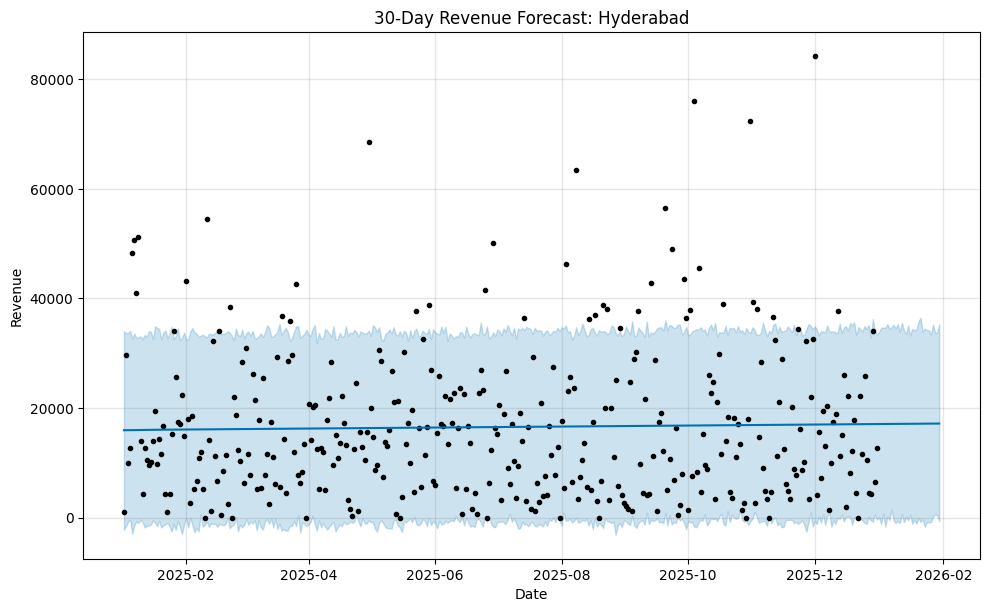

In [24]:
regions_to_forecast = ["Delhi", "Mumbai", "Bengaluru", "Chennai", "Hyderabad"]
region_forecasts = {}

for region_name in regions_to_forecast:
    transactions = df.loc[
        df["Region"].astype("string").str.strip().str.casefold()
        == region_name.casefold(),
        ["InvoiceDate", "Revenue"],
    ].copy()
    if transactions.empty:
        raise ValueError(f"No sales records found for region: {region_name}")

    transactions["InvoiceDate"] = pd.to_datetime(
        transactions["InvoiceDate"], errors="raise"
    )
    transactions["Revenue"] = pd.to_numeric(transactions["Revenue"], errors="raise")
    daily_sales = (
        transactions.groupby("InvoiceDate", as_index=False)["Revenue"]
        .sum()
        .rename(columns={"InvoiceDate": "ds", "Revenue": "y"})
        .sort_values("ds")
    )
    all_days = pd.date_range(daily_sales["ds"].min(), daily_sales["ds"].max(), freq="D")
    daily_sales = (
        daily_sales.set_index("ds")
        .reindex(all_days, fill_value=0)
        .rename_axis("ds")
        .reset_index()
    )

    region_model = Prophet(
        yearly_seasonality=False,
        weekly_seasonality=False,
        daily_seasonality=False,
    )
    region_model.fit(daily_sales)
    future = region_model.make_future_dataframe(periods=30, freq="D")
    forecast = region_model.predict(future)
    future_forecast = forecast.loc[
        forecast["ds"] > daily_sales["ds"].max(),
        ["ds", "yhat", "yhat_lower", "yhat_upper"],
    ].copy()
    prediction_columns = ["yhat", "yhat_lower", "yhat_upper"]
    if not np.isfinite(future_forecast[prediction_columns]).all().all():
        raise ValueError(f"The {region_name} forecast contains non-finite values")
    future_forecast[prediction_columns] = future_forecast[prediction_columns].clip(lower=0)
    region_forecasts[region_name] = future_forecast

    print(
        f"{region_name}: {len(transactions):,} transactions, "
        f"{len(daily_sales):,} daily observations; "
        f"forecasting the next {len(future_forecast)} days."
    )
    display(future_forecast.round(2))
    region_model.plot(forecast)
    plt.title(f"30-Day Revenue Forecast: {region_name}")
    plt.xlabel("Date")
    plt.ylabel("Revenue")
    plt.show()

## Category-wise revenue forecasts

This cell trains a separate daily revenue model for Beauty, Electronics, Fashion, Grocery, and Home. Each category gets its own 30-day forecast and chart.

09:48:36 - cmdstanpy - INFO - Chain [1] start processing
09:48:36 - cmdstanpy - INFO - Chain [1] done processing


Beauty: 1,121 transactions, 364 daily observations; forecasting the next 30 days.


,ds,yhat,yhat_lower,yhat_upper
364,2025-12-31,2782.73,95.79,5287.39
365,2026-01-01,2781.82,349.87,5538.58
366,2026-01-02,2780.92,0.00,5540.25
367,2026-01-03,2780.01,338.46,5628.44
368,2026-01-04,2779.11,129.65,5441.71
369,2026-01-05,2778.20,82.44,5434.36
370,2026-01-06,2777.30,184.20,5429.87
371,2026-01-07,2776.40,141.17,5568.50
372,2026-01-08,2775.49,0.00,5447.40
373,2026-01-09,2774.59,158.28,5507.17


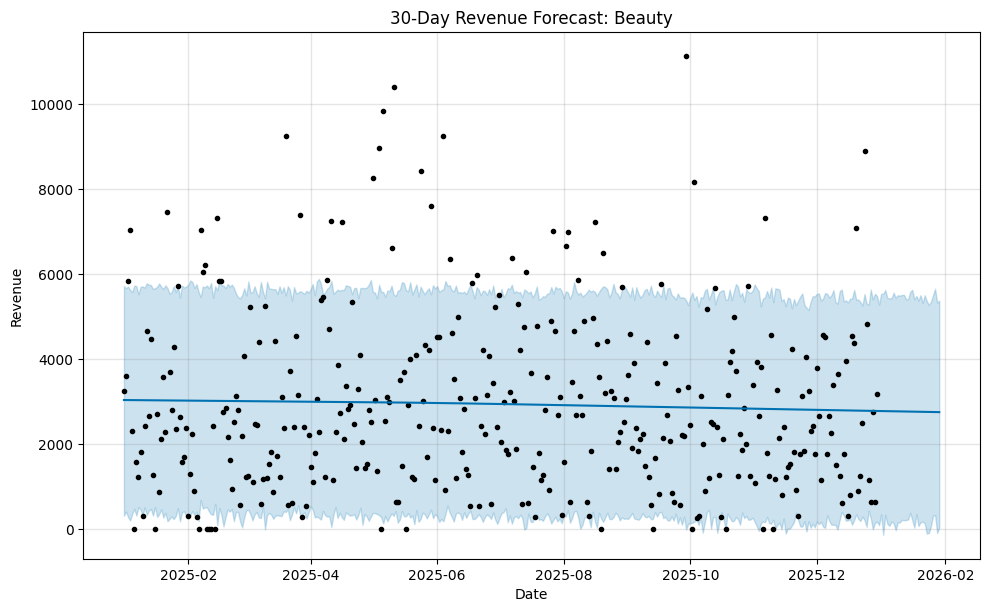

09:48:36 - cmdstanpy - INFO - Chain [1] start processing
09:48:36 - cmdstanpy - INFO - Chain [1] done processing


Electronics: 1,183 transactions, 365 daily observations; forecasting the next 30 days.


,ds,yhat,yhat_lower,yhat_upper
365,2026-01-01,23315.01,3329.50,41611.18
366,2026-01-02,23320.51,5326.59,41883.19
367,2026-01-03,23326.00,3898.68,42611.18
368,2026-01-04,23331.50,4584.15,43907.70
369,2026-01-05,23336.99,4897.67,42217.16
370,2026-01-06,23342.49,4092.96,43345.58
371,2026-01-07,23347.98,5006.42,42166.38
372,2026-01-08,23353.48,3713.92,42793.58
373,2026-01-09,23358.97,4615.42,42554.56
374,2026-01-10,23364.47,4642.36,42642.81


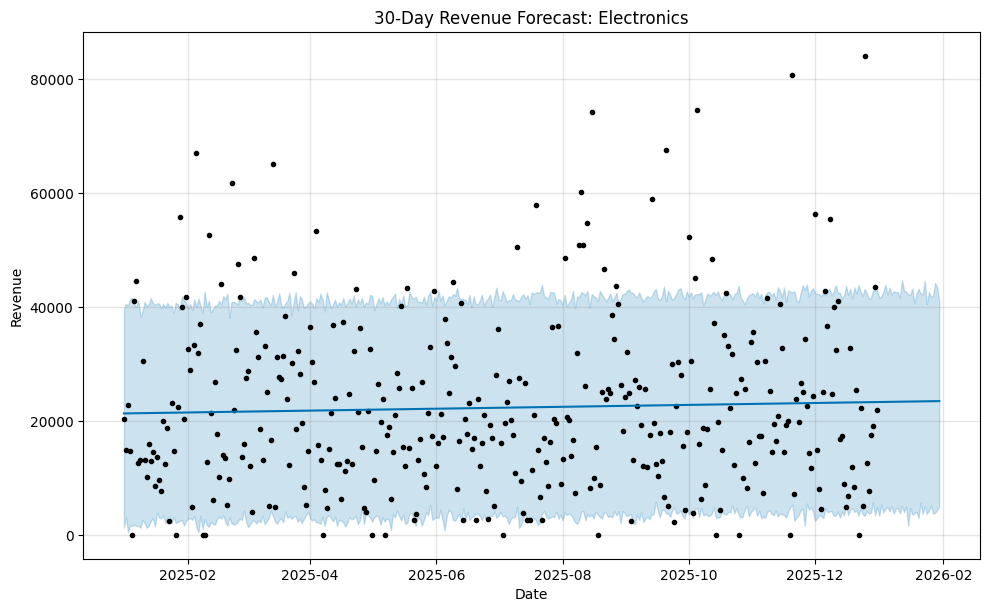

09:48:36 - cmdstanpy - INFO - Chain [1] start processing
09:48:36 - cmdstanpy - INFO - Chain [1] done processing


Fashion: 1,242 transactions, 365 daily observations; forecasting the next 30 days.


,ds,yhat,yhat_lower,yhat_upper
365,2026-01-01,17796.08,734.57,33823.52
366,2026-01-02,17794.52,1704.74,32869.68
367,2026-01-03,17792.97,1663.53,34563.77
368,2026-01-04,17791.41,2487.59,35188.32
369,2026-01-05,17789.86,1170.73,33256.95
370,2026-01-06,17788.30,2408.58,33448.84
371,2026-01-07,17786.75,1733.33,34797.53
372,2026-01-08,17785.19,2069.50,33804.02
373,2026-01-09,17783.64,1428.11,34769.46
374,2026-01-10,17782.08,1863.98,33075.05


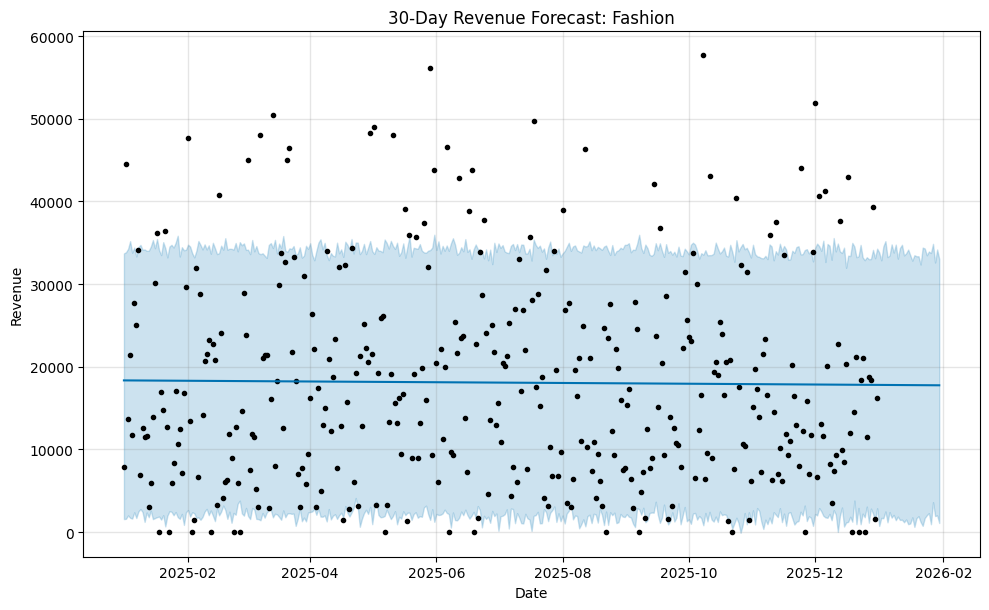

09:48:36 - cmdstanpy - INFO - Chain [1] start processing
09:48:36 - cmdstanpy - INFO - Chain [1] done processing


Grocery: 1,224 transactions, 365 daily observations; forecasting the next 30 days.


,ds,yhat,yhat_lower,yhat_upper
365,2026-01-01,3413.52,185.11,6448.47
366,2026-01-02,3411.58,365.75,6523.89
367,2026-01-03,3409.64,150.24,6418.00
368,2026-01-04,3407.70,352.39,6347.46
369,2026-01-05,3405.75,186.97,6537.63
370,2026-01-06,3403.81,246.16,6444.37
371,2026-01-07,3401.87,31.96,6378.64
372,2026-01-08,3399.93,283.03,6855.28
373,2026-01-09,3397.99,296.36,6859.88
374,2026-01-10,3396.04,314.89,6477.63


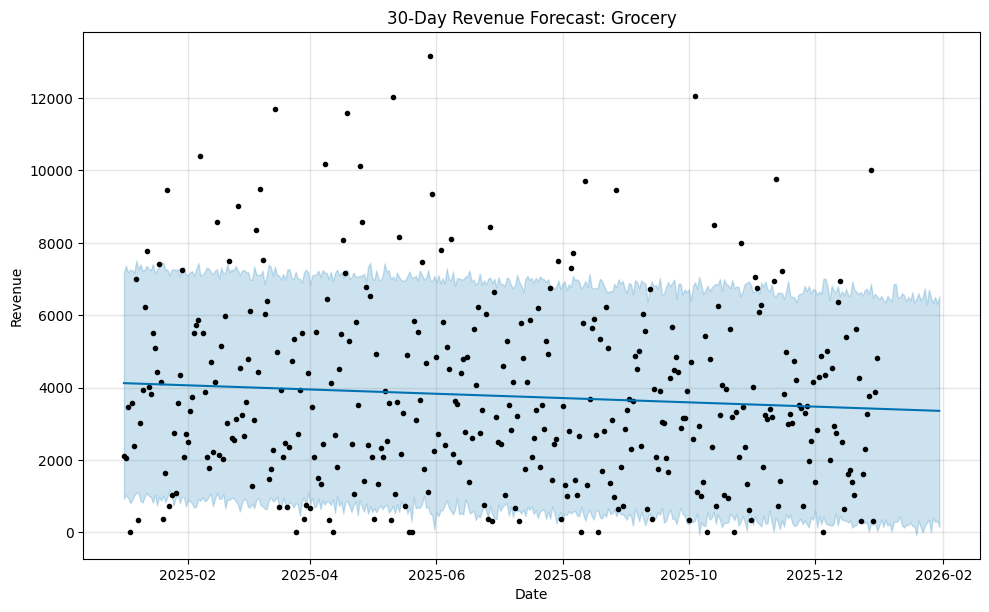

09:48:37 - cmdstanpy - INFO - Chain [1] start processing
09:48:37 - cmdstanpy - INFO - Chain [1] done processing


Home: 1,230 transactions, 365 daily observations; forecasting the next 30 days.


,ds,yhat,yhat_lower,yhat_upper
365,2026-01-01,33737.83,4472.66,60714.02
366,2026-01-02,33751.67,6451.36,59392.21
367,2026-01-03,33765.52,5302.46,59623.94
368,2026-01-04,33779.37,5085.79,61497.51
369,2026-01-05,33793.21,7697.83,62976.80
370,2026-01-06,33807.06,6296.29,62134.82
371,2026-01-07,33820.91,6099.71,62384.03
372,2026-01-08,33834.75,4477.85,60812.74
373,2026-01-09,33848.60,7167.17,62313.57
374,2026-01-10,33862.45,6415.94,59518.29


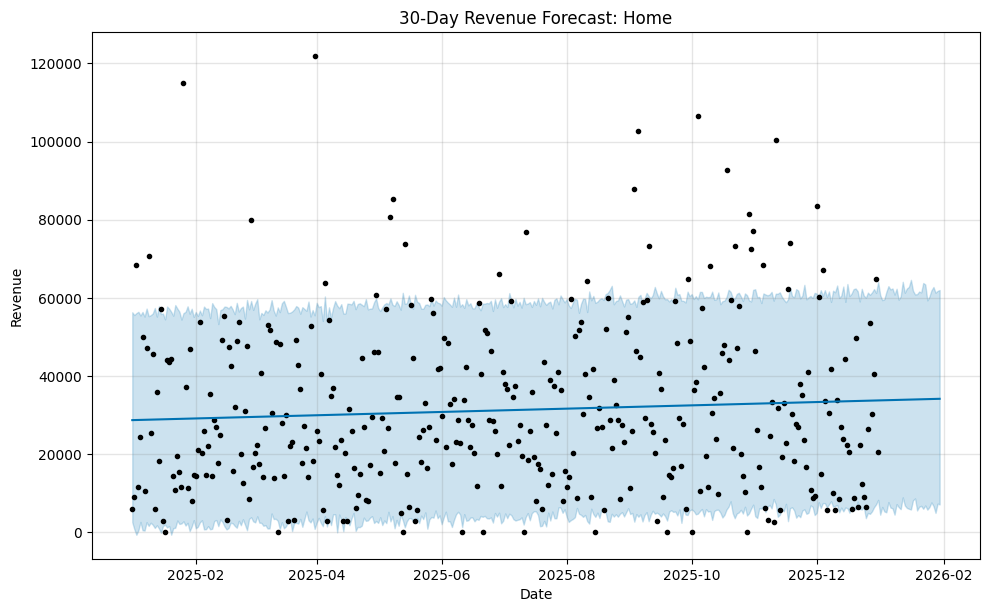

In [25]:
categories_to_forecast = ["Beauty", "Electronics", "Fashion", "Grocery", "Home"]
category_forecasts = {}

for category_name in categories_to_forecast:
    category_transactions = df.loc[
        df["Category"].astype("string").str.strip().str.casefold()
        == category_name.casefold(),
        ["InvoiceDate", "Revenue"],
    ].copy()
    if category_transactions.empty:
        raise ValueError(f"No sales records found for category: {category_name}")

    category_transactions["InvoiceDate"] = pd.to_datetime(
        category_transactions["InvoiceDate"], errors="raise"
    )
    category_transactions["Revenue"] = pd.to_numeric(
        category_transactions["Revenue"], errors="raise"
    )
    category_daily = (
        category_transactions.groupby("InvoiceDate", as_index=False)["Revenue"]
        .sum()
        .rename(columns={"InvoiceDate": "ds", "Revenue": "y"})
        .sort_values("ds")
    )
    all_days = pd.date_range(
        category_daily["ds"].min(), category_daily["ds"].max(), freq="D"
    )
    category_daily = (
        category_daily.set_index("ds")
        .reindex(all_days, fill_value=0)
        .rename_axis("ds")
        .reset_index()
    )

    category_model = Prophet(
        yearly_seasonality=False,
        weekly_seasonality=False,
        daily_seasonality=False,
    )
    category_model.fit(category_daily)
    category_future = category_model.make_future_dataframe(periods=30, freq="D")
    category_forecast = category_model.predict(category_future)
    category_future_forecast = category_forecast.loc[
        category_forecast["ds"] > category_daily["ds"].max(),
        ["ds", "yhat", "yhat_lower", "yhat_upper"],
    ].copy()
    prediction_columns = ["yhat", "yhat_lower", "yhat_upper"]
    if not np.isfinite(category_future_forecast[prediction_columns]).all().all():
        raise ValueError(f"The {category_name} forecast contains non-finite values")
    category_future_forecast[prediction_columns] = category_future_forecast[
        prediction_columns
    ].clip(lower=0)
    category_forecasts[category_name] = category_future_forecast

    print(
        f"{category_name}: {len(category_transactions):,} transactions, "
        f"{len(category_daily):,} daily observations; "
        f"forecasting the next {len(category_future_forecast)} days."
    )
    display(category_future_forecast.round(2))
    category_model.plot(category_forecast)
    plt.title(f"30-Day Revenue Forecast: {category_name}")
    plt.xlabel("Date")
    plt.ylabel("Revenue")
    plt.show()

## Category forecasts within each region

This section forecasts each category separately within each region: 25 independent models in total. The results are kept separately by `(region, category)`, displayed one region at a time, and plotted as five category panels for each region.

09:48:37 - cmdstanpy - INFO - Chain [1] start processing
09:48:37 - cmdstanpy - INFO - Chain [1] done processing
09:48:37 - cmdstanpy - INFO - Chain [1] start processing
09:48:37 - cmdstanpy - INFO - Chain [1] done processing
09:48:37 - cmdstanpy - INFO - Chain [1] start processing
09:48:37 - cmdstanpy - INFO - Chain [1] done processing
09:48:37 - cmdstanpy - INFO - Chain [1] start processing
09:48:37 - cmdstanpy - INFO - Chain [1] done processing
09:48:37 - cmdstanpy - INFO - Chain [1] start processing
09:48:37 - cmdstanpy - INFO - Chain [1] done processing


Delhi: completed separate forecasts for 5 categories.


,Category,ds,yhat,yhat_lower,yhat_upper
0,Beauty,2025-12-29,476.93,0.0,1617.56
1,Beauty,2025-12-30,476.68,0.0,1651.83
2,Beauty,2025-12-31,476.43,0.0,1561.20
3,Beauty,2026-01-01,476.18,0.0,1577.39
4,Beauty,2026-01-02,475.92,0.0,1560.61
...,...,...,...,...,...
145,Home,2026-01-25,5595.14,0.0,17447.27
146,Home,2026-01-26,5591.67,0.0,17015.15
147,Home,2026-01-27,5588.21,0.0,17326.43
148,Home,2026-01-28,5584.74,0.0,16403.40


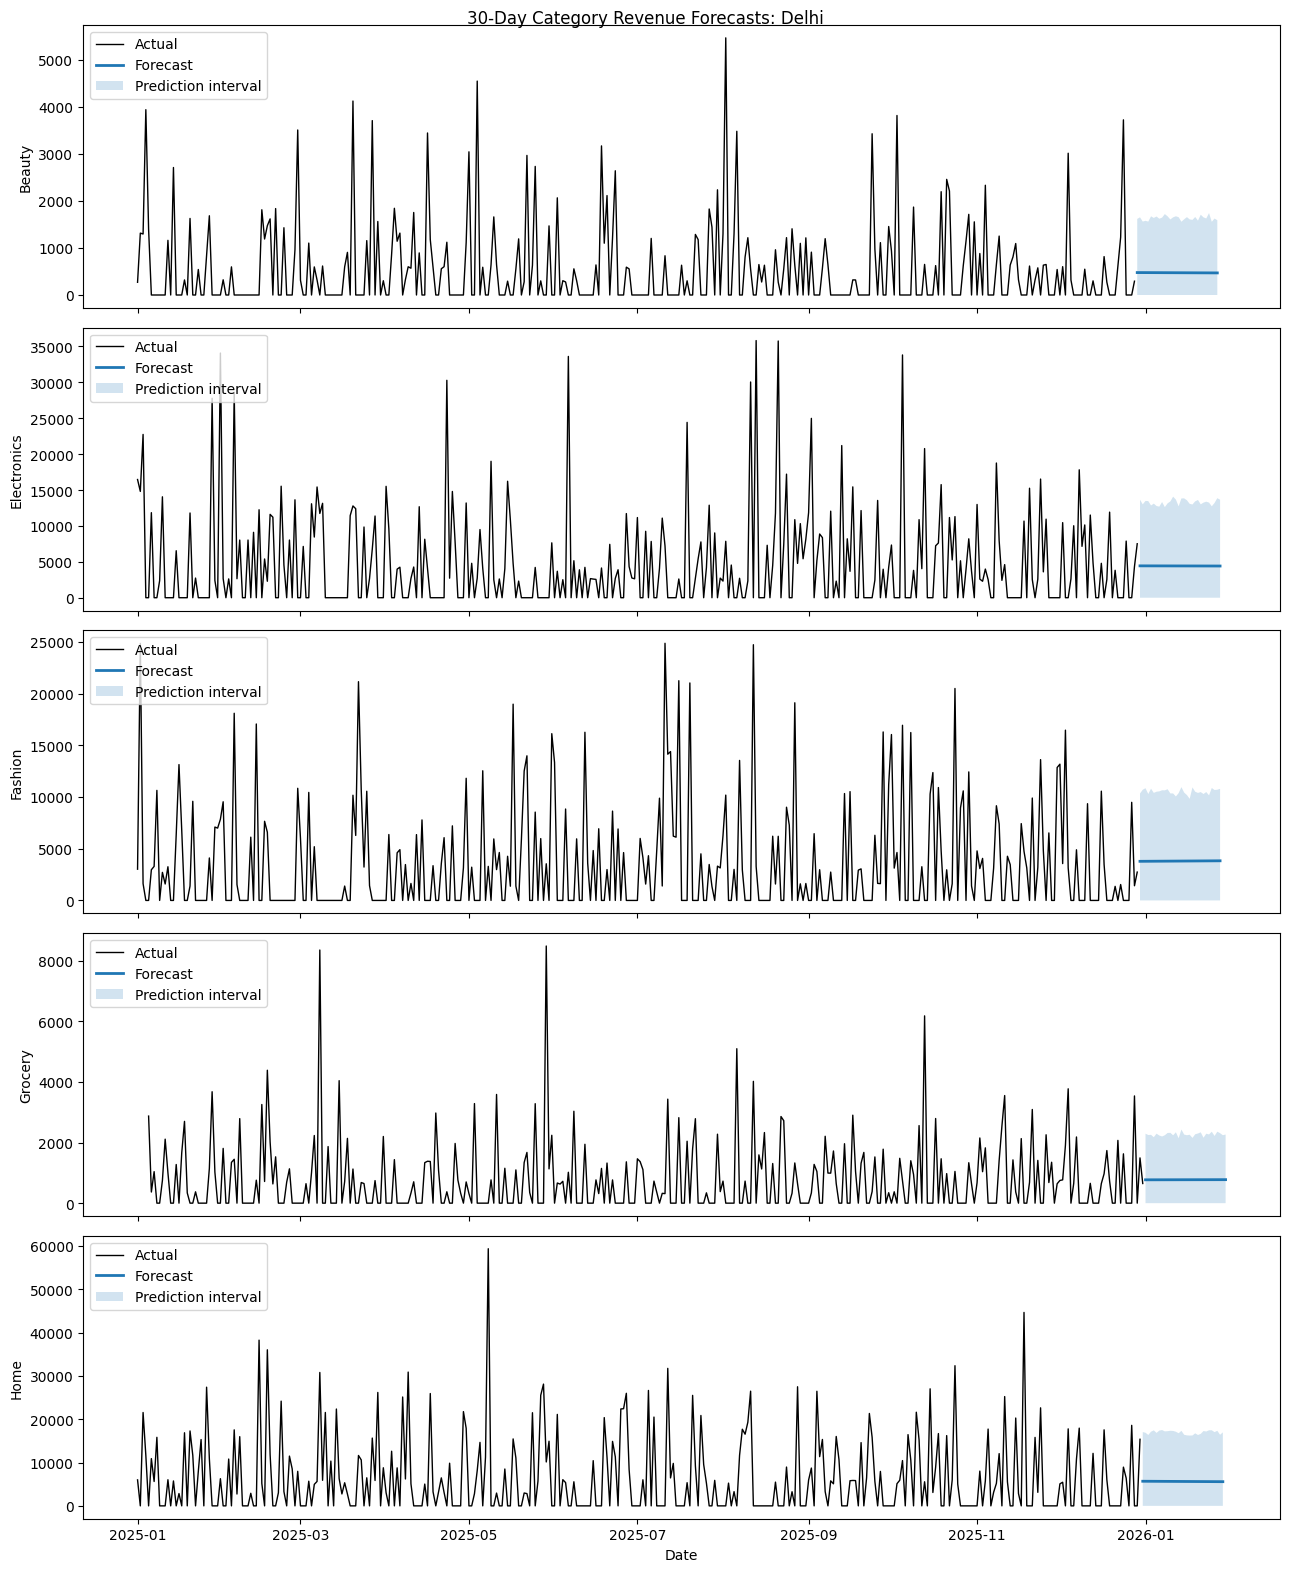

09:48:37 - cmdstanpy - INFO - Chain [1] start processing
09:48:37 - cmdstanpy - INFO - Chain [1] done processing
09:48:38 - cmdstanpy - INFO - Chain [1] start processing
09:48:38 - cmdstanpy - INFO - Chain [1] done processing
09:48:38 - cmdstanpy - INFO - Chain [1] start processing
09:48:38 - cmdstanpy - INFO - Chain [1] done processing
09:48:38 - cmdstanpy - INFO - Chain [1] start processing
09:48:38 - cmdstanpy - INFO - Chain [1] done processing
09:48:38 - cmdstanpy - INFO - Chain [1] start processing
09:48:38 - cmdstanpy - INFO - Chain [1] done processing


Mumbai: completed separate forecasts for 5 categories.


,Category,ds,yhat,yhat_lower,yhat_upper
0,Beauty,2025-12-29,561.39,0.0,1676.04
1,Beauty,2025-12-30,560.93,0.0,1700.99
2,Beauty,2025-12-31,560.48,0.0,1693.42
3,Beauty,2026-01-01,560.02,0.0,1681.48
4,Beauty,2026-01-02,559.57,0.0,1688.40
...,...,...,...,...,...
145,Home,2026-01-26,6603.11,0.0,16594.54
146,Home,2026-01-27,6607.37,0.0,16402.43
147,Home,2026-01-28,6611.63,0.0,17389.00
148,Home,2026-01-29,6615.89,0.0,17189.93


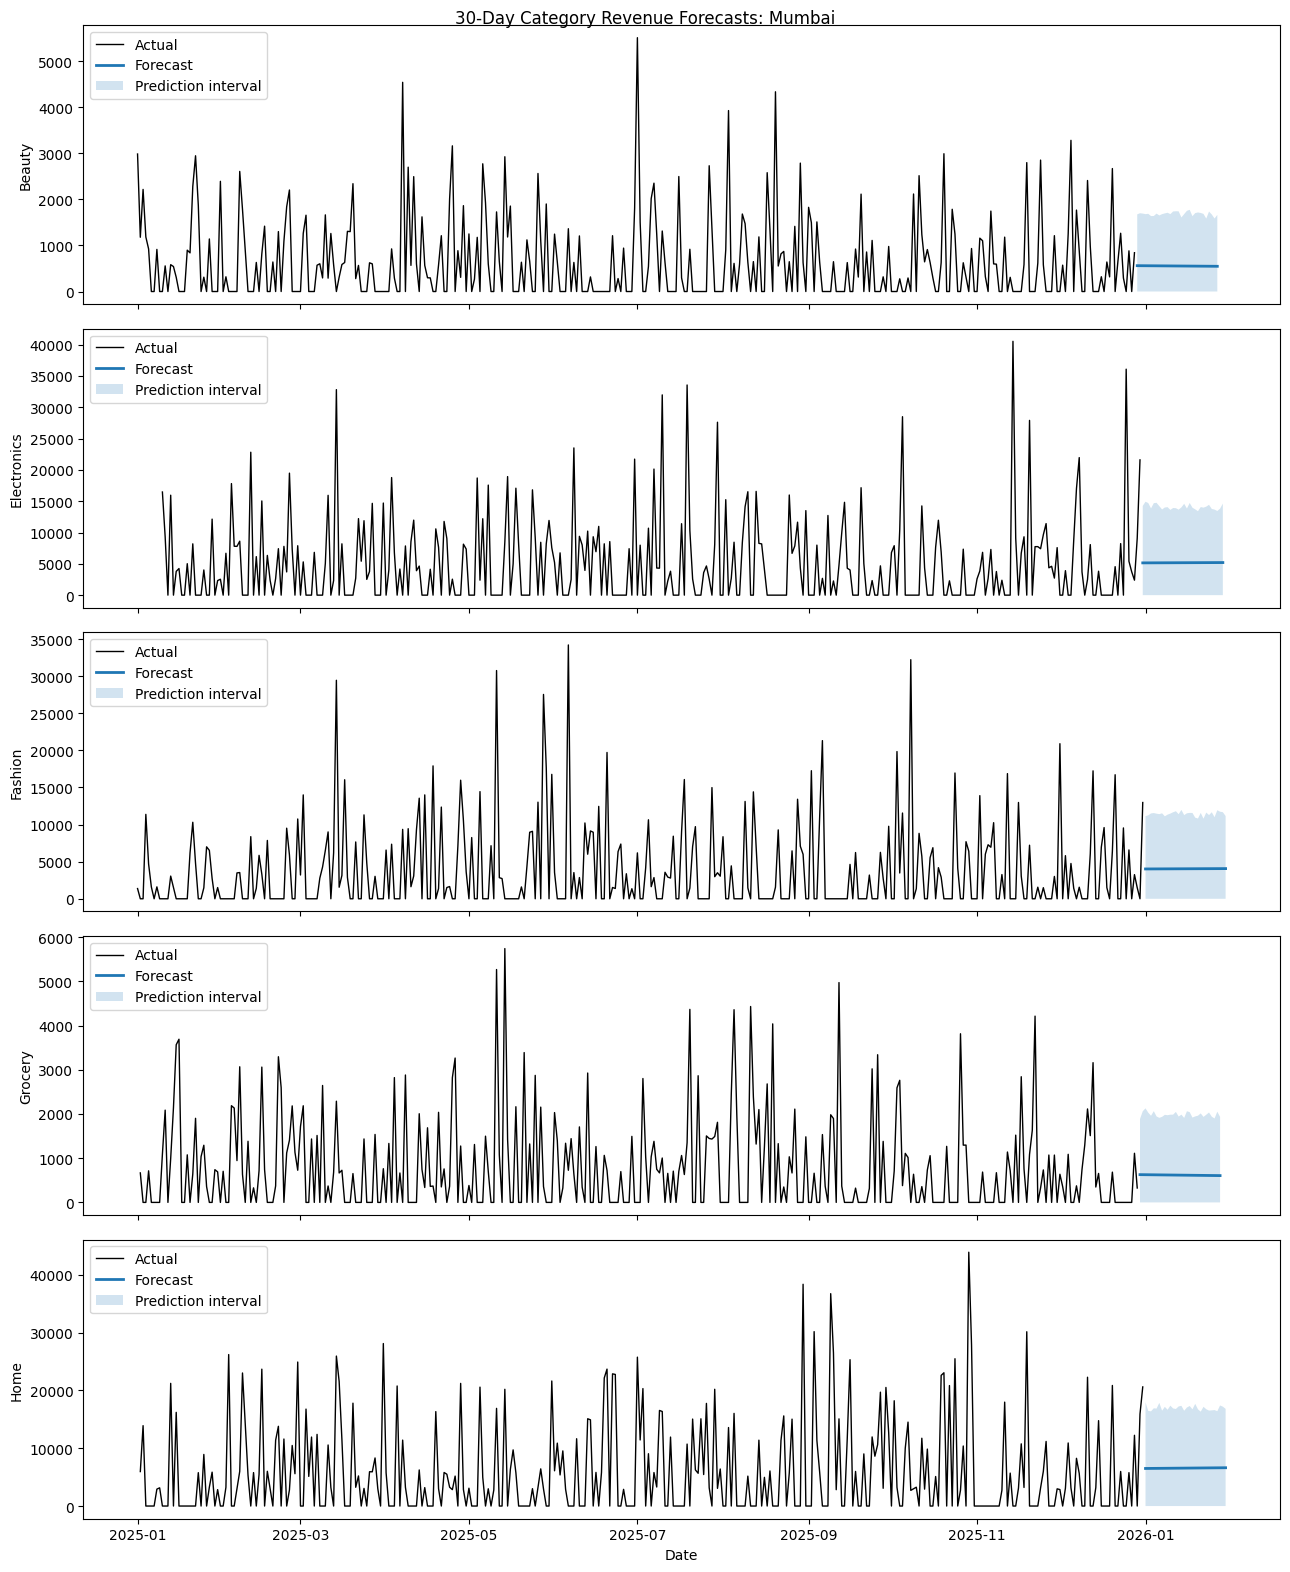

09:48:38 - cmdstanpy - INFO - Chain [1] start processing
09:48:38 - cmdstanpy - INFO - Chain [1] done processing
09:48:38 - cmdstanpy - INFO - Chain [1] start processing
09:48:38 - cmdstanpy - INFO - Chain [1] done processing
09:48:38 - cmdstanpy - INFO - Chain [1] start processing
09:48:38 - cmdstanpy - INFO - Chain [1] done processing
09:48:38 - cmdstanpy - INFO - Chain [1] start processing
09:48:38 - cmdstanpy - INFO - Chain [1] done processing
09:48:38 - cmdstanpy - INFO - Chain [1] start processing
09:48:38 - cmdstanpy - INFO - Chain [1] done processing


Bengaluru: completed separate forecasts for 5 categories.


,Category,ds,yhat,yhat_lower,yhat_upper
0,Beauty,2025-12-31,638.39,0.0,1822.11
1,Beauty,2026-01-01,638.66,0.0,1790.64
2,Beauty,2026-01-02,638.94,0.0,1834.64
3,Beauty,2026-01-03,639.21,0.0,1801.95
4,Beauty,2026-01-04,639.48,0.0,1840.12
...,...,...,...,...,...
145,Home,2026-01-25,5533.62,0.0,16504.51
146,Home,2026-01-26,5534.57,0.0,16165.53
147,Home,2026-01-27,5535.52,0.0,16394.11
148,Home,2026-01-28,5536.47,0.0,16357.51


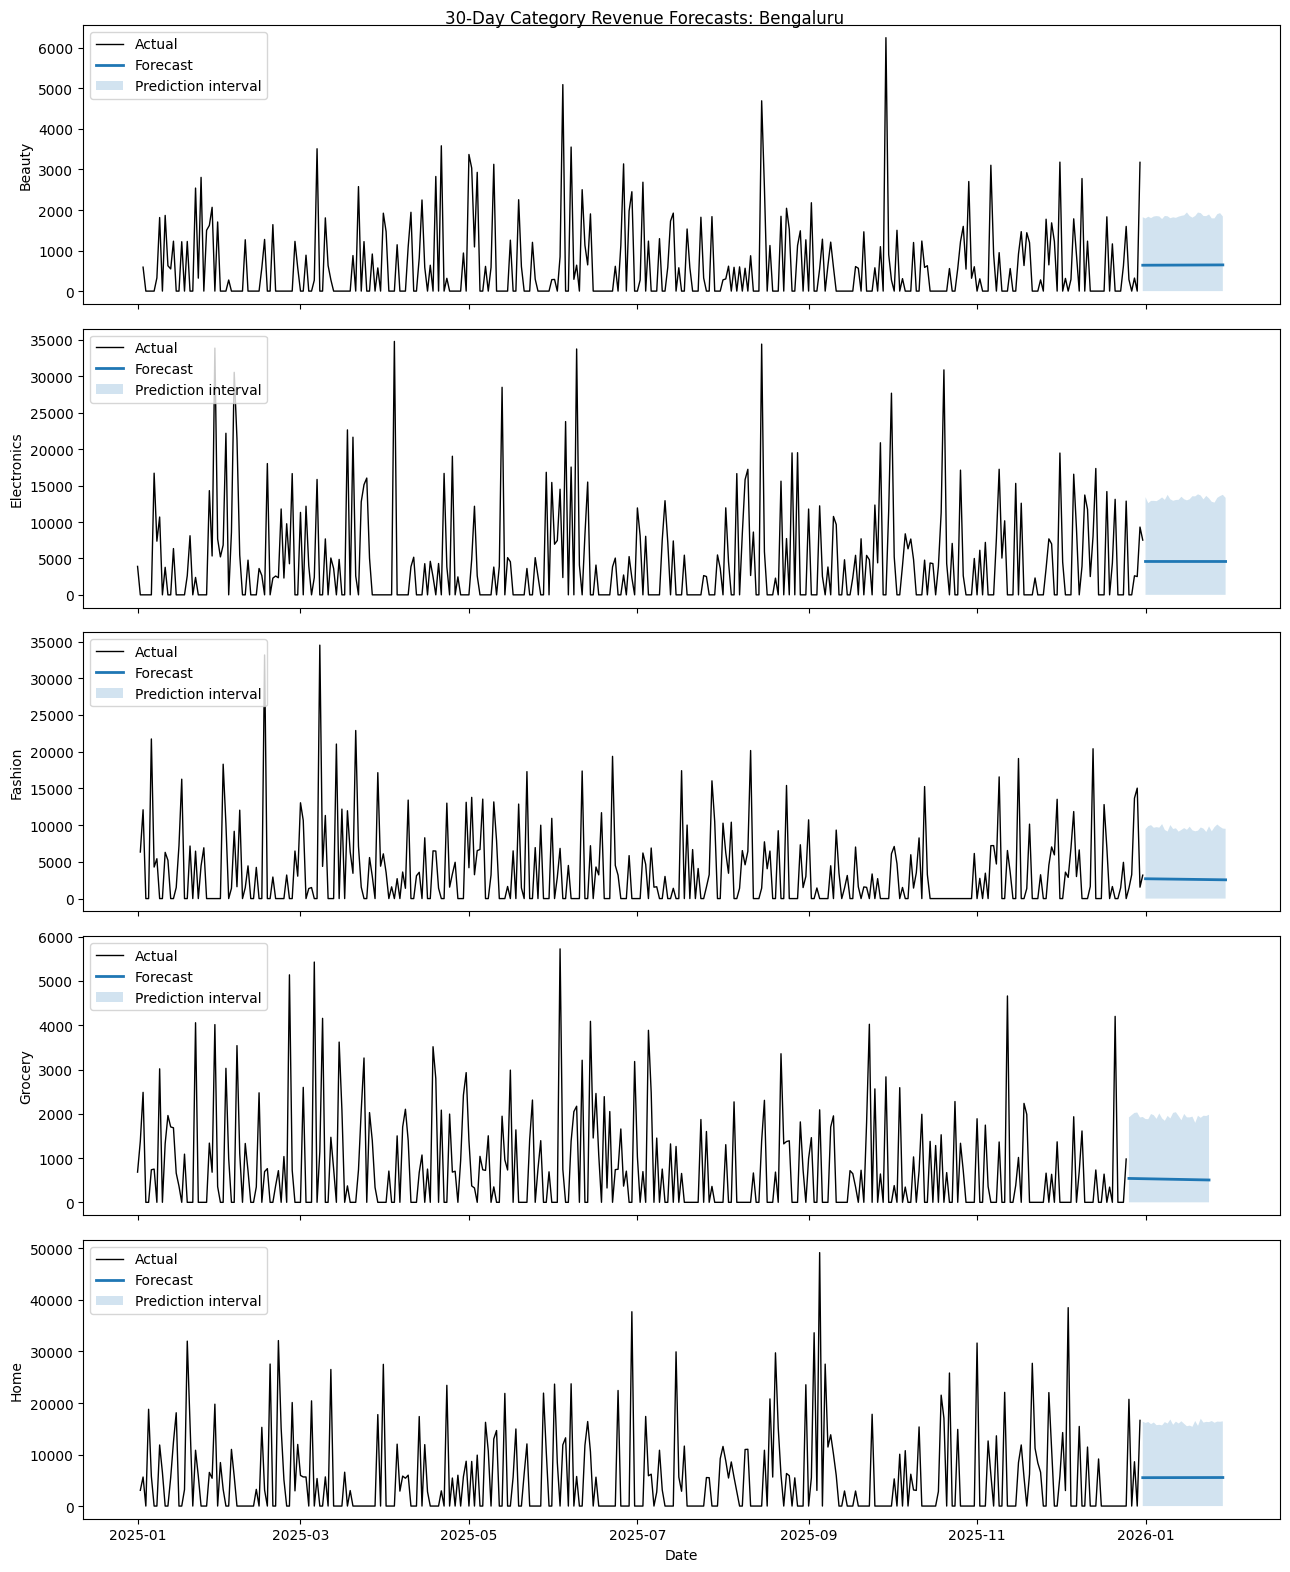

09:48:39 - cmdstanpy - INFO - Chain [1] start processing
09:48:39 - cmdstanpy - INFO - Chain [1] done processing
09:48:39 - cmdstanpy - INFO - Chain [1] start processing
09:48:39 - cmdstanpy - INFO - Chain [1] done processing
09:48:39 - cmdstanpy - INFO - Chain [1] start processing
09:48:39 - cmdstanpy - INFO - Chain [1] done processing
09:48:39 - cmdstanpy - INFO - Chain [1] start processing
09:48:39 - cmdstanpy - INFO - Chain [1] done processing
09:48:39 - cmdstanpy - INFO - Chain [1] start processing
09:48:39 - cmdstanpy - INFO - Chain [1] done processing


Chennai: completed separate forecasts for 5 categories.


,Category,ds,yhat,yhat_lower,yhat_upper
0,Beauty,2025-12-30,524.21,0.0,1611.32
1,Beauty,2025-12-31,523.78,0.0,1769.21
2,Beauty,2026-01-01,523.36,0.0,1714.42
3,Beauty,2026-01-02,522.94,0.0,1666.91
4,Beauty,2026-01-03,522.51,0.0,1638.40
...,...,...,...,...,...
145,Home,2026-01-25,8210.91,0.0,21171.38
146,Home,2026-01-26,8215.89,0.0,21121.07
147,Home,2026-01-27,8220.87,0.0,21969.76
148,Home,2026-01-28,8225.85,0.0,21675.53


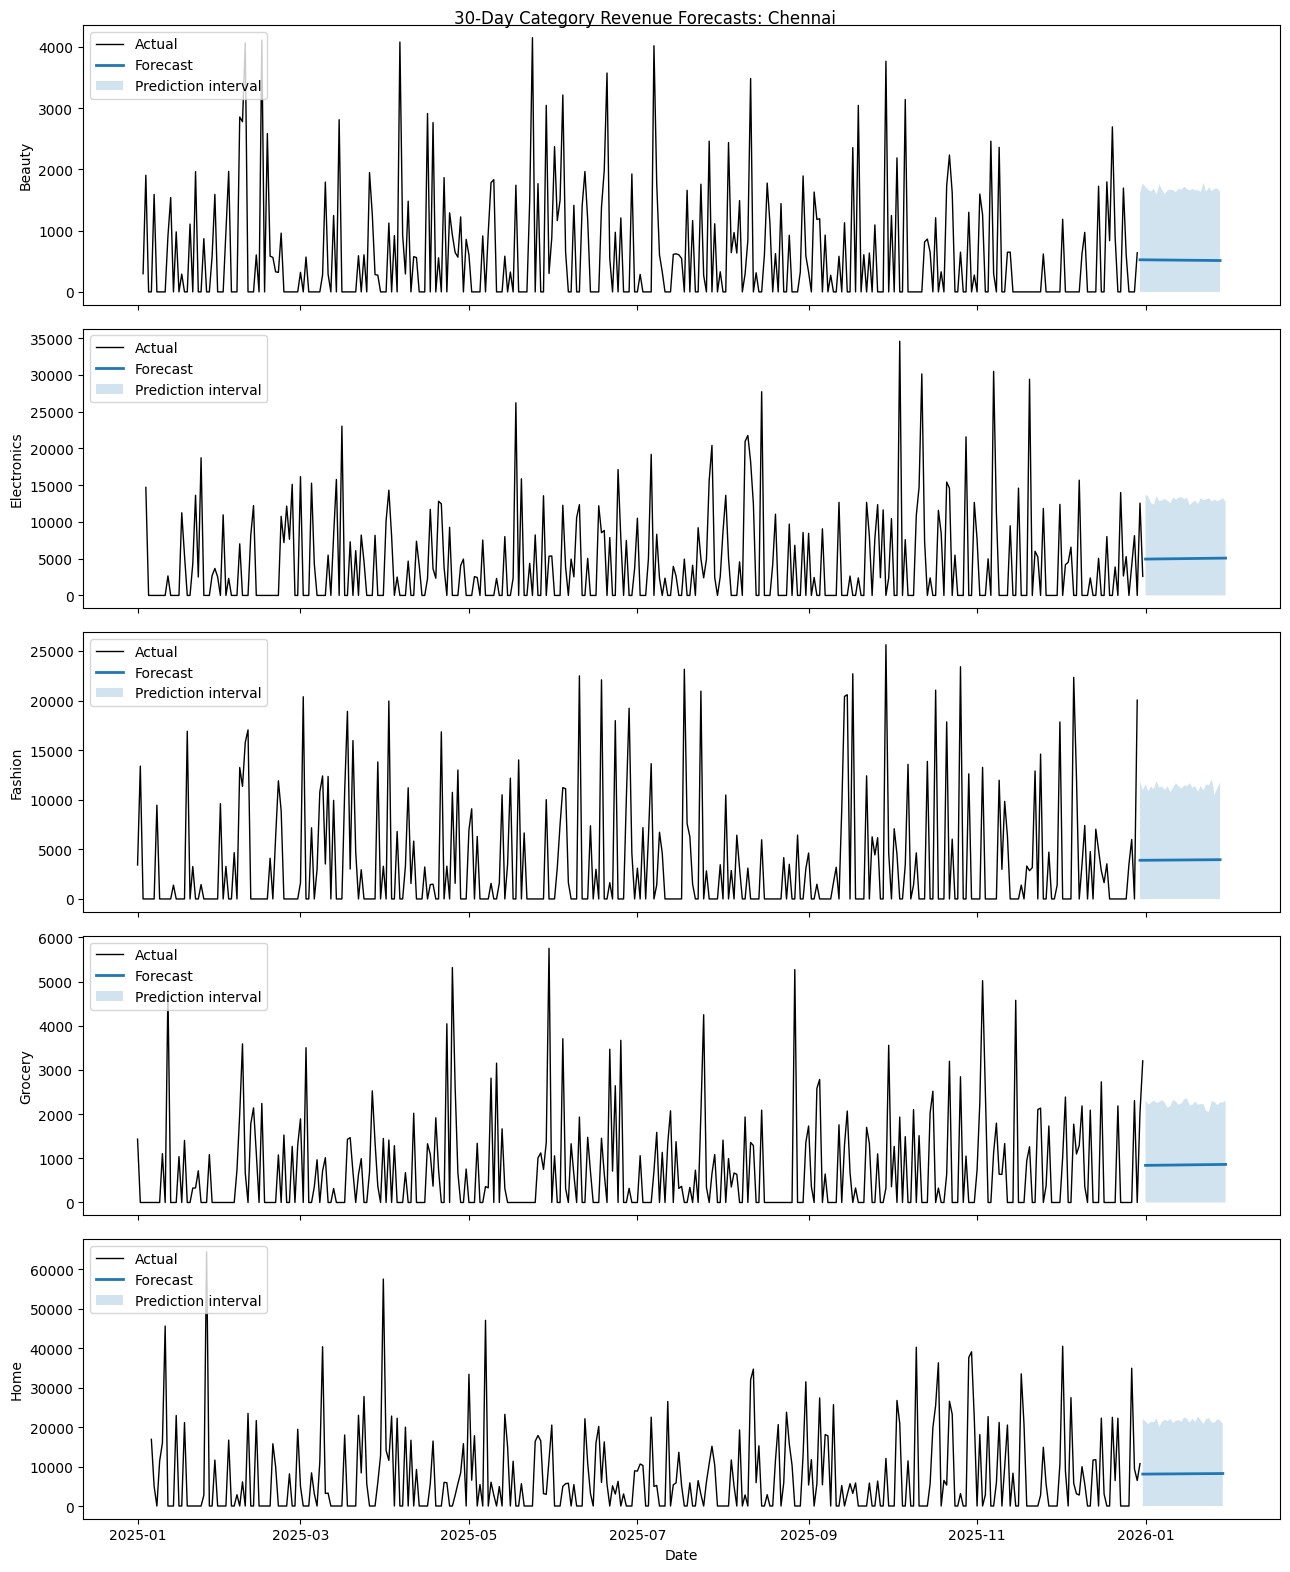

09:48:39 - cmdstanpy - INFO - Chain [1] start processing
09:48:39 - cmdstanpy - INFO - Chain [1] done processing
09:48:40 - cmdstanpy - INFO - Chain [1] start processing
09:48:40 - cmdstanpy - INFO - Chain [1] done processing
09:48:40 - cmdstanpy - INFO - Chain [1] start processing
09:48:40 - cmdstanpy - INFO - Chain [1] done processing
09:48:40 - cmdstanpy - INFO - Chain [1] start processing
09:48:40 - cmdstanpy - INFO - Chain [1] done processing
09:48:40 - cmdstanpy - INFO - Chain [1] start processing
09:48:40 - cmdstanpy - INFO - Chain [1] done processing


Hyderabad: completed separate forecasts for 5 categories.


,Category,ds,yhat,yhat_lower,yhat_upper
0,Beauty,2025-12-29,623.35,0.0,1890.64
1,Beauty,2025-12-30,623.57,0.0,1965.51
2,Beauty,2025-12-31,623.79,0.0,1959.27
3,Beauty,2026-01-01,624.01,0.0,1974.40
4,Beauty,2026-01-02,624.22,0.0,1911.15
...,...,...,...,...,...
145,Home,2026-01-25,7740.58,0.0,21779.18
146,Home,2026-01-26,7744.61,0.0,19872.41
147,Home,2026-01-27,7748.64,0.0,21061.52
148,Home,2026-01-28,7752.67,0.0,21104.03


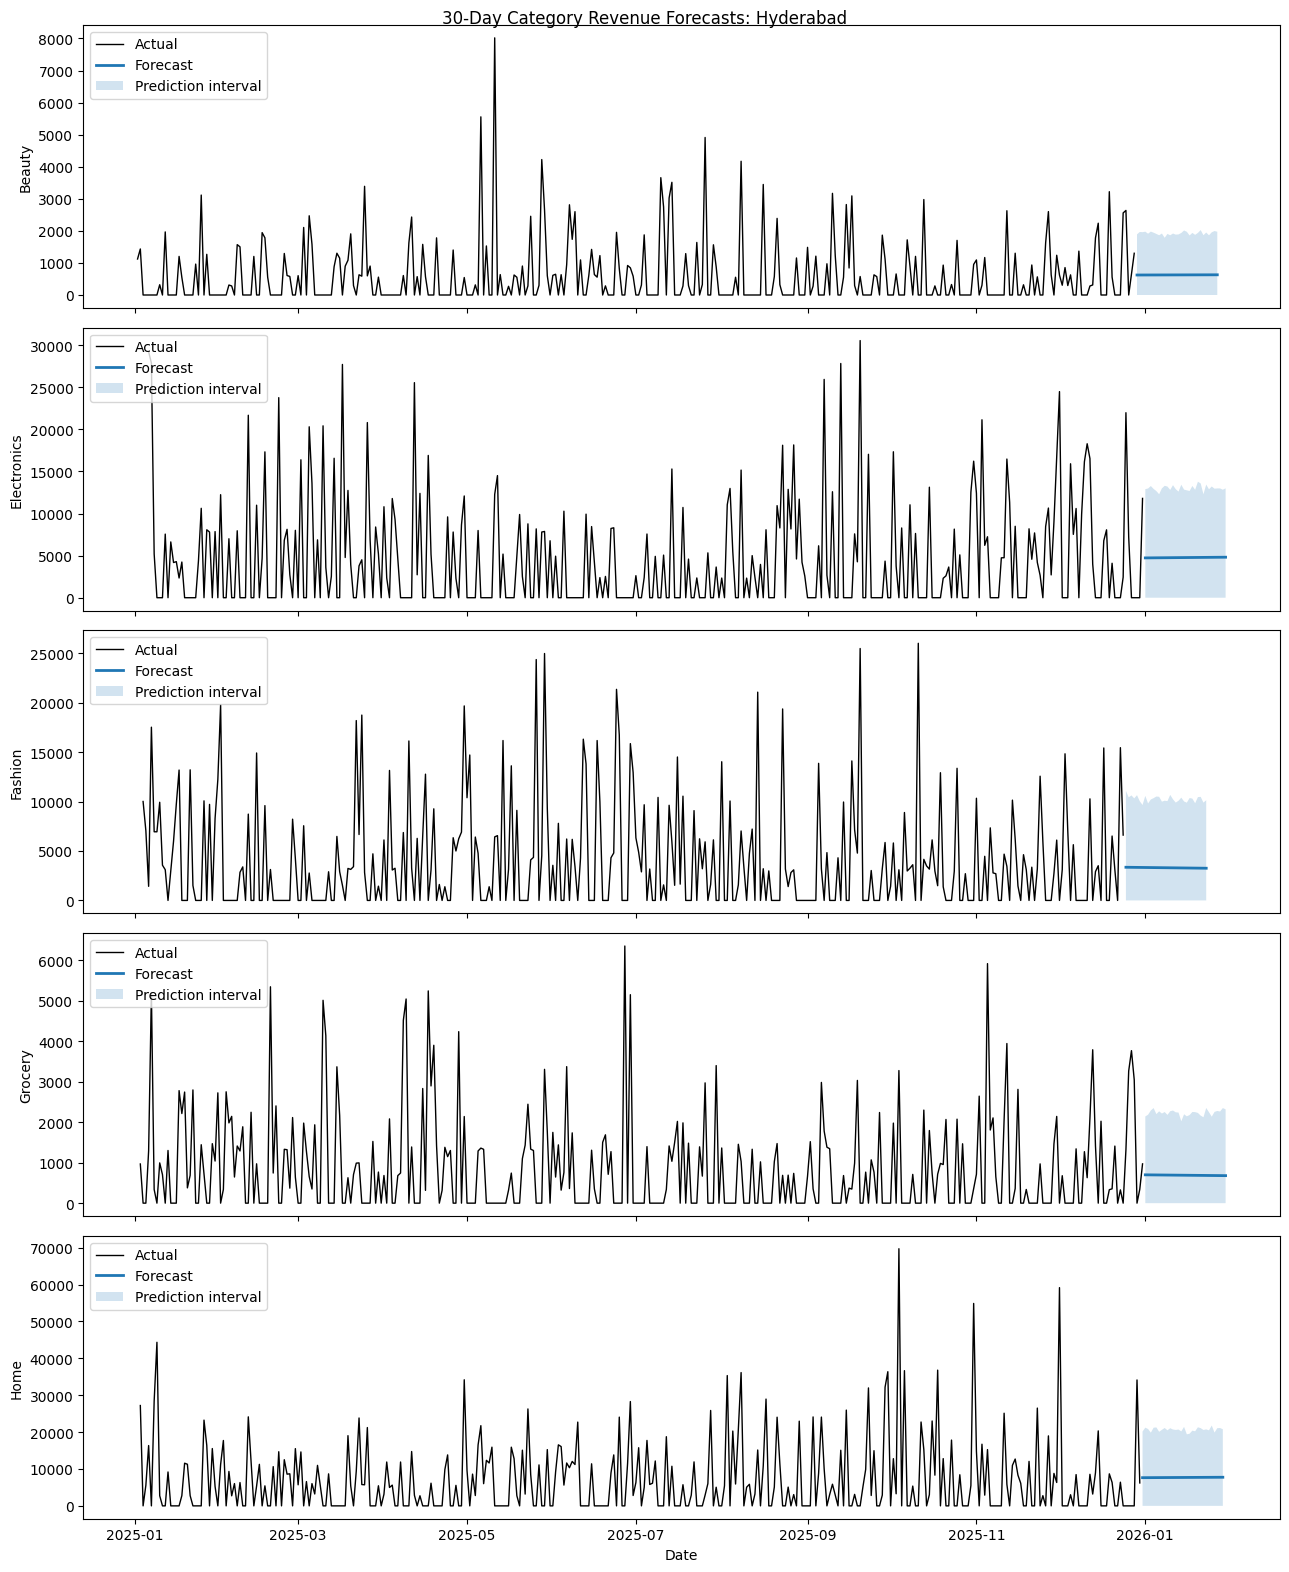

In [26]:
regions_to_forecast = ["Delhi", "Mumbai", "Bengaluru", "Chennai", "Hyderabad"]
categories_to_forecast = ["Beauty", "Electronics", "Fashion", "Grocery", "Home"]
forecast_days = 30
category_region_forecasts = {}
category_region_history = {}

for region_name in regions_to_forecast:
    for category_name in categories_to_forecast:
        transactions = df.loc[
            df["Region"].astype("string").str.strip().str.casefold()
            == region_name.casefold(),
            ["Category", "InvoiceDate", "Revenue"],
        ]
        transactions = transactions.loc[
            transactions["Category"].astype("string").str.strip().str.casefold()
            == category_name.casefold()
        ].copy()
        if transactions.empty:
            raise ValueError(
                f"No sales records found for {category_name} in {region_name}"
            )

        transactions["InvoiceDate"] = pd.to_datetime(
            transactions["InvoiceDate"], errors="raise"
        )
        transactions["Revenue"] = pd.to_numeric(
            transactions["Revenue"], errors="raise"
        )
        daily_sales = (
            transactions.groupby("InvoiceDate", as_index=False)["Revenue"]
            .sum()
            .rename(columns={"InvoiceDate": "ds", "Revenue": "y"})
            .sort_values("ds")
        )
        all_days = pd.date_range(
            daily_sales["ds"].min(), daily_sales["ds"].max(), freq="D"
        )
        daily_sales = (
            daily_sales.set_index("ds")
            .reindex(all_days, fill_value=0)
            .rename_axis("ds")
            .reset_index()
        )

        model = Prophet(
            yearly_seasonality=False,
            weekly_seasonality=False,
            daily_seasonality=False,
        )
        model.fit(daily_sales)
        future = model.make_future_dataframe(periods=forecast_days, freq="D")
        forecast = model.predict(future)
        future_forecast = forecast.loc[
            forecast["ds"] > daily_sales["ds"].max(),
            ["ds", "yhat", "yhat_lower", "yhat_upper"],
        ].copy()
        prediction_columns = ["yhat", "yhat_lower", "yhat_upper"]
        if len(future_forecast) != forecast_days:
            raise ValueError(
                f"Expected {forecast_days} forecast days for "
                f"{category_name} in {region_name}, got {len(future_forecast)}"
            )
        if not np.isfinite(future_forecast[prediction_columns]).all().all():
            raise ValueError(
                f"The {category_name} forecast for {region_name} "
                "contains non-finite values"
            )
        future_forecast[prediction_columns] = future_forecast[
            prediction_columns
        ].clip(lower=0)
        category_region_forecasts[(region_name, category_name)] = future_forecast
        category_region_history[(region_name, category_name)] = daily_sales

    print(
        f"{region_name}: completed separate forecasts for "
        f"{len(categories_to_forecast)} categories."
    )
    region_results = pd.concat(
        [
            result.assign(Category=category)
            for (region, category), result in category_region_forecasts.items()
            if region == region_name
        ],
        ignore_index=True,
    )
    display(
        region_results[
            ["Category", "ds", "yhat", "yhat_lower", "yhat_upper"]
        ].round(2)
    )

    fig, axes = plt.subplots(
        len(categories_to_forecast), 1, figsize=(13, 16), sharex=True
    )
    for ax, category in zip(axes, categories_to_forecast):
        history = category_region_history[(region_name, category)]
        future_forecast = category_region_forecasts[(region_name, category)]
        ax.plot(history["ds"], history["y"], color="black", linewidth=1, label="Actual")
        ax.plot(
            future_forecast["ds"],
            future_forecast["yhat"],
            linewidth=2,
            label="Forecast",
        )
        ax.fill_between(
            future_forecast["ds"],
            future_forecast["yhat_lower"],
            future_forecast["yhat_upper"],
            alpha=0.2,
            label="Prediction interval",
        )
        ax.set_ylabel(category)
        ax.legend(loc="upper left")
    axes[-1].set_xlabel("Date")
    fig.suptitle(f"30-Day Category Revenue Forecasts: {region_name}")
    fig.tight_layout()
    plt.show()